HD 160691: Joint fit with RVs and mock Gaia DR4 astrometry

We first fit the 4 planet system using measured radial velocities.
We then simulate Gaia DR4 observations and fit them jointly
with the RVs to test how well the mock astrometry recovers the injected
orbital inclinations and nodes.

## 1. Load and inspect the radial velocities

The binned RVs come from the local `roman-orbits` checkout at
`all_fits/HD_160691/data/all_rvs_binned.csv`. The file contains 487
measurements from seven instruments. We convert the epochs to MJD and
the velocities and uncertainties from m/s to km/s.
The preview subtracts each instrument's median for display.

487 RVs from 7 instruments
Time baseline: 21.3 years
Instruments: coralie, harps0, harps0-sep, harps1, pfspost, pfspre, ucles


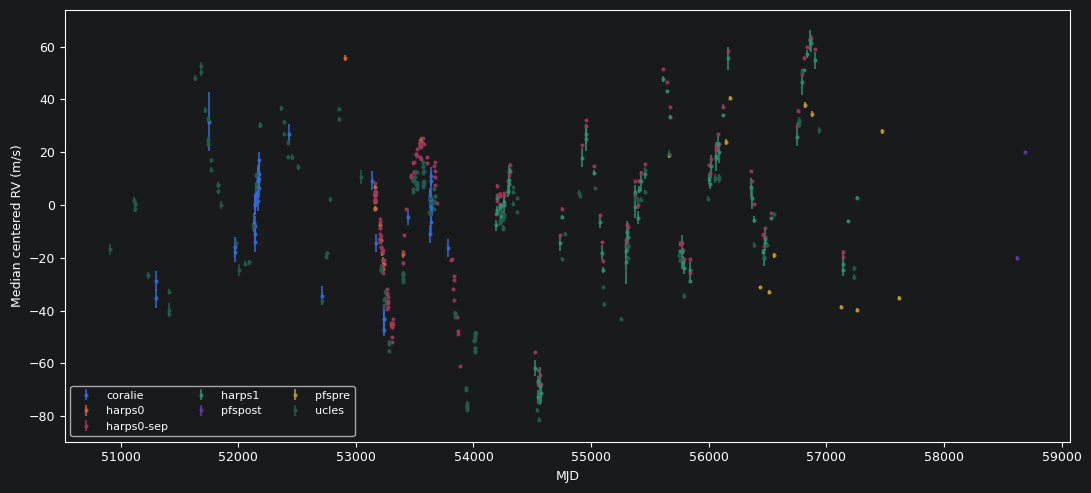

In [2]:
from pathlib import Path

import astropy
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from astropy import units as u
from astropy.table import Table
from astropy.time import Time
from radvel.basis import Basis
from pathlib import Path
import importlib
from orbitize import DATADIR, simulate_dr4 as dr4_sim
from copy import deepcopy
import numpy as np
from orbitize import gaia, priors, sampler, system

import orbitize
from orbitize import DATADIR, gaia, plot, priors, read_input, sampler, system
from orbitize.basis import tp_to_tau

rng = np.random.default_rng(90)

rv_file = (
    Path.home() / "Projects" / "roman-orbits"
    / "all_fits" / "HD_160691" / "data" / "all_rvs_binned.csv"
)

raw_rv = Table.read(rv_file, format="ascii.csv")
rv_input = Table({
    "epoch": np.asarray(raw_rv["time"], dtype=float) - 2_400_000.5,
    "object": np.zeros(len(raw_rv), dtype=int),  # 0 = host star
    "rv": np.asarray(raw_rv["mnvel"], dtype=float) / 1_000,
    "rv_err": np.asarray(raw_rv["errvel"], dtype=float) / 1_000,
    "instrument": np.asarray(raw_rv["tel"], dtype=str),
})

data_table = read_input.read_file(rv_input)
data_table.sort("epoch")
# Plot RVs

instruments = np.unique(data_table["instrument"])
baseline_years = np.ptp(data_table["epoch"]) / 365.25
print(f"{len(data_table)} RVs from {len(instruments)} instruments")
print(f"Time baseline: {baseline_years:.1f} years")
print("Instruments:", ", ".join(instruments))

fig, ax = plt.subplots(figsize=(11, 5))
for instrument in instruments:
    use = data_table["instrument"] == instrument
    ax.errorbar(
        data_table["epoch"][use],
        1_000 * (
            data_table["quant1"][use]
            - np.median(data_table["quant1"][use])
        ),
        yerr=1_000 * data_table["quant1_err"][use],
        fmt=".",
        ms=4,
        alpha=0.75,
        label=instrument,
    )
ax.set(xlabel="MJD", ylabel="Median centered RV (m/s)")
ax.legend(ncol=3, fontsize=8)
fig.tight_layout()

## 2. Set up the four-planet RV fit

We use Gaussian priors for the host star’s mass and parallax:

- **Stellar mass:** $1.13 \pm 0.02\,M_\odot$, from
  [Bonfanti et al. (2015)](https://doi.org/10.1051/0004-6361/201424951),
  as adopted in Table 1 of
  [Benedict et al. (2022)](https://doi.org/10.3847/1538-3881/ac6ac8).
- **Parallax:** $64.0853 \pm 0.0904$ mas, from Gaia EDR3, as reported for
  HD 160691 in [Laliotis et al. (2023), §5.17](https://doi.org/10.3847/1538-3881/acc067).


In [3]:
from orbitize import system

# CREATE SYSTEM HD 160691
# Preserve the ordering in the existing RadVel posterior:
# 1 ≈ 645 days, 2 ≈ 9.64 days, 3 ≈ 309 days, 4 ≈ 4040 days.
num_secondary_bodies = 4

stellar_mass = 1.13   # Msun
mass_err = 0.02       # Msun
plx = 64.0853        # mas
plx_err = 0.0904      # mas

# MCMC parameters: RV only fit
num_temps = 8
num_walkers = 96
num_threads = 10
burn_steps = 1_000
num_steps = 3_000
thin = 1

tau_ref_epoch = 58_849  # MJD (2020-01-01)

my_system = system.System(
    num_secondary_bodies,
    data_table,
    stellar_mass,
    plx,
    mass_err=mass_err,
    plx_err=plx_err,
    fit_secondary_mass=True,
    tau_ref_epoch=tau_ref_epoch,
    fitting_basis="SemiAmp",
)

## 3. Set the RV priors and initialize the walkers

We use broad priors for all four planets, with log-uniform priors on
orbital period and RV semi-amplitude and isotropic priors on orbital
orientation. Each instrument has its own RV zero point and jitter.

We initialize each walker from one draw of the archived HD 160691
RadVel chain in `roman-planets-table`. The archived draws
set the starting positions only. Inclination and longitude of the
ascending node start from their broad priors.

In [4]:
# Override only the priors that differ from the SemiAmp defaults.
idx = my_system.param_idx
n_planets = my_system.num_secondary_bodies

for body in range(1, n_planets + 1):
    my_system.sys_priors[idx[f"per{body}"]] = priors.LogUniformPrior(
        1 / 365.25, 100_000 / 365.25,  # 1–100,000 days, in years
    )
    my_system.sys_priors[idx[f"ecc{body}"]] = priors.UniformPrior(0.0, 0.99)
    my_system.sys_priors[idx[f"K{body}"]] = priors.LogUniformPrior(1e-5, 1.0)  # km/s

for inst in my_system.rv_instruments:
    my_system.sys_priors[idx[f"gamma_{inst}"]] = priors.UniformPrior(-50.0, 50.0)
    my_system.sys_priors[idx[f"sigma_{inst}"]] = priors.UniformPrior(0.0, 0.2)

m = sampler.MCMC(
    my_system, num_temps=num_temps, num_walkers=num_walkers, num_threads=num_threads,
)

# Start each walker from one archived RV draw. Inclination and LAN keep their prior draws.
chain_path = (
    Path.home() / "Projects" / "roman-planets-table" / "orbit_fits"
    / "HD_160691" / "HD160691_radvel_chains.csv.bz2"
)
chain = pd.read_csv(chain_path)
positions = m.curr_pos.reshape(-1, m.num_params).copy()
walker_idx = m.sampled_param_idx
rows = np.random.default_rng(160691).integers(len(chain), size=len(positions))
draws = Basis("per tc secosw sesinw k", n_planets).to_synth(chain.iloc[rows].copy())

for body in range(1, n_planets + 1):
    period = draws[f"per{body}"].to_numpy() / 365.25
    positions[:, walker_idx[f"per{body}"]] = period
    positions[:, walker_idx[f"ecc{body}"]] = draws[f"e{body}"]
    positions[:, walker_idx[f"K{body}"]] = draws[f"k{body}"] / 1_000
    # Convert RadVel's stellar periastron angle to the companion convention.
    positions[:, walker_idx[f"aop{body}"]] = (draws[f"w{body}"] + np.pi) % (2 * np.pi)
    positions[:, walker_idx[f"tau{body}"]] = tp_to_tau(
        draws[f"tp{body}"].to_numpy() - 2_400_000.5, m.system.tau_ref_epoch, period,
    )

for inst in m.system.rv_instruments:
    positions[:, walker_idx[f"gamma_{inst}"]] = draws[f"gamma_{inst}"] / 1_000
    positions[:, walker_idx[f"sigma_{inst}"]] = draws[f"jit_{inst}"] / 1_000

m.curr_pos = positions.reshape(m.curr_pos.shape)
m.check_prior_support()

## 4. Run the RV only fit

We already initialized the sampler, now we will run it for the RV-only case.

In [5]:
run = m.run_sampler(
    num_walkers * num_steps,
    burn_steps=burn_steps,
)

rv_post = m.results.post

print(f"Posterior samples: {len(rv_post)}")
print(f"Cold chain acceptance: {run.acceptance_fraction[0].mean():.3f}")

Starting Burn in


/Users/clary/Projects/orbitize-mu-ara/orbitize/hipparcos.py:234: SyntaxWarning: invalid escape sequence '\s'
  path_to_iad_file, skiprows=9, sep="\s+", nrows=1
/Users/clary/Projects/orbitize-mu-ara/orbitize/hipparcos.py:234: SyntaxWarning: invalid escape sequence '\s'
  path_to_iad_file, skiprows=9, sep="\s+", nrows=1
/Users/clary/Projects/orbitize-mu-ara/orbitize/hipparcos.py:234: SyntaxWarning: invalid escape sequence '\s'
  path_to_iad_file, skiprows=9, sep="\s+", nrows=1
/Users/clary/Projects/orbitize-mu-ara/orbitize/hipparcos.py:248: SyntaxWarning: invalid escape sequence '\s'
  path_to_iad_file, skiprows=5, sep="\s+", nrows=1
/Users/clary/Projects/orbitize-mu-ara/orbitize/hipparcos.py:248: SyntaxWarning: invalid escape sequence '\s'
  path_to_iad_file, skiprows=5, sep="\s+", nrows=1
/Users/clary/Projects/orbitize-mu-ara/orbitize/hipparcos.py:248: SyntaxWarning: invalid escape sequence '\s'
  path_to_iad_file, skiprows=5, sep="\s+", nrows=1
/Users/clary/Projects/orbitize-mu-ara/or

/Users/clary/Projects/orbitize-mu-ara/orbitize/priors.py:417: RuntimeWarning: invalid value encountered in log
  lnprob = -np.log((element_array * normalizer))


/Users/clary/Projects/orbitize-mu-ara/orbitize/priors.py:417: RuntimeWarning: invalid value encountered in log
  lnprob = -np.log((element_array * normalizer))


/Users/clary/Projects/orbitize-mu-ara/orbitize/priors.py:417: RuntimeWarning: invalid value encountered in log
  lnprob = -np.log((element_array * normalizer))


/Users/clary/Projects/orbitize-mu-ara/orbitize/priors.py:417: RuntimeWarning: invalid value encountered in log
  lnprob = -np.log((element_array * normalizer))


... (3 outputs left out)

/Users/clary/Projects/orbitize-mu-ara/orbitize/priors.py:417: RuntimeWarning: invalid value encountered in log
  lnprob = -np.log((element_array * normalizer))


/Users/clary/Projects/orbitize-mu-ara/orbitize/priors.py:417: RuntimeWarning: invalid value encountered in log
  lnprob = -np.log((element_array * normalizer))


/Users/clary/Projects/orbitize-mu-ara/orbitize/priors.py:417: RuntimeWarning: invalid value encountered in log
  lnprob = -np.log((element_array * normalizer))


1000/1000 steps of burn-in complete
Burn in complete. Sampling posterior now.
3000/3000 steps completed
Run complete
Posterior samples: 288000
Cold chain acceptance: 0.050


## 5. Compare the RV posteriors with the archived fit

We make one corner plot per planet, in the notebook’s order
(b, d, e, c).
Orange marks the medians from the archived RadVel fits.

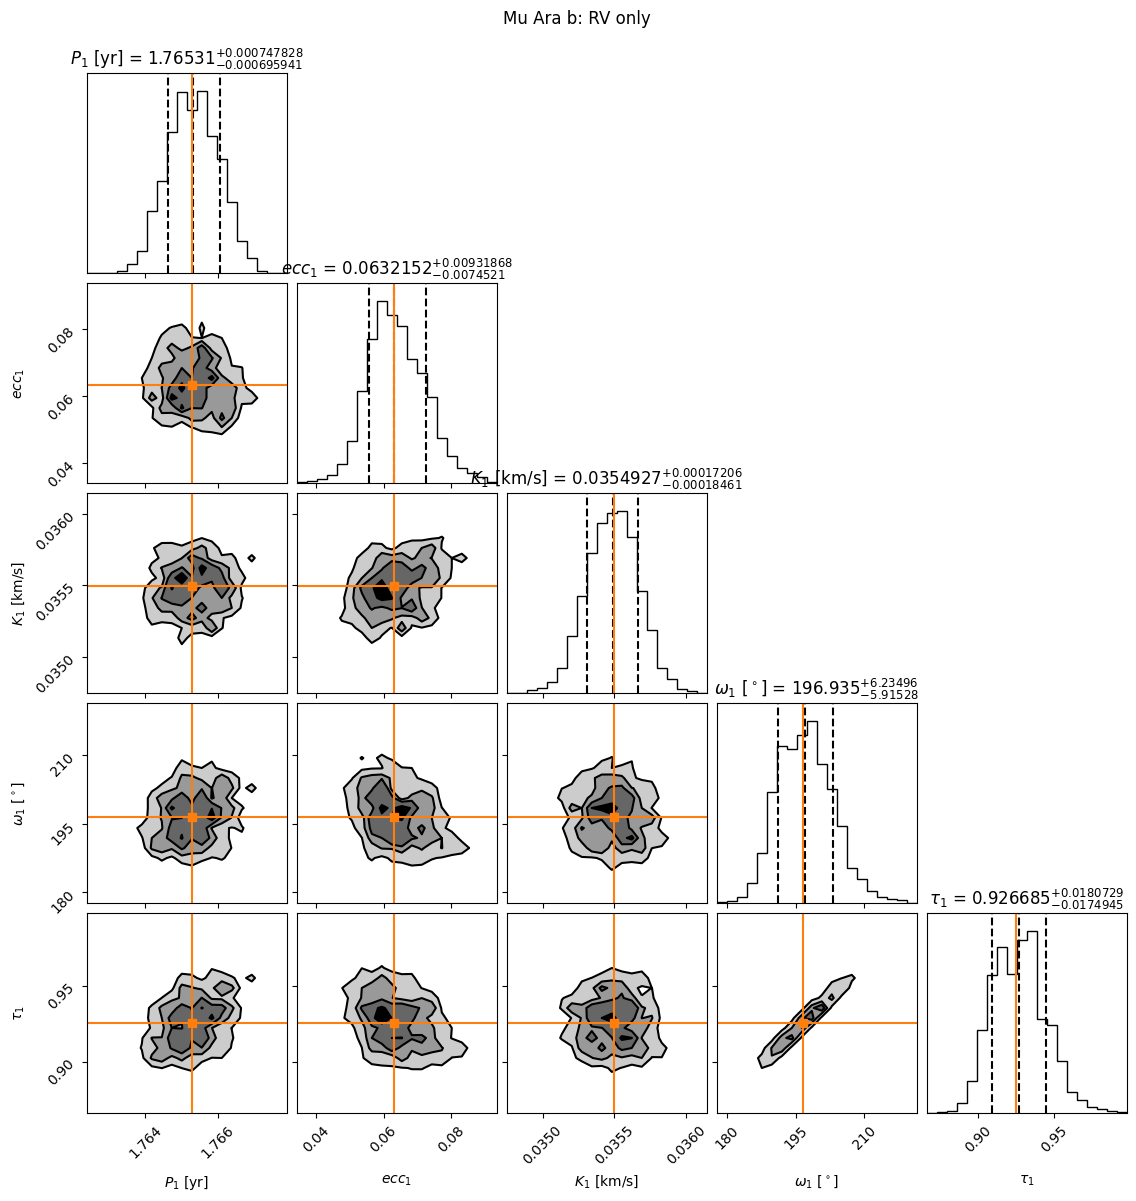

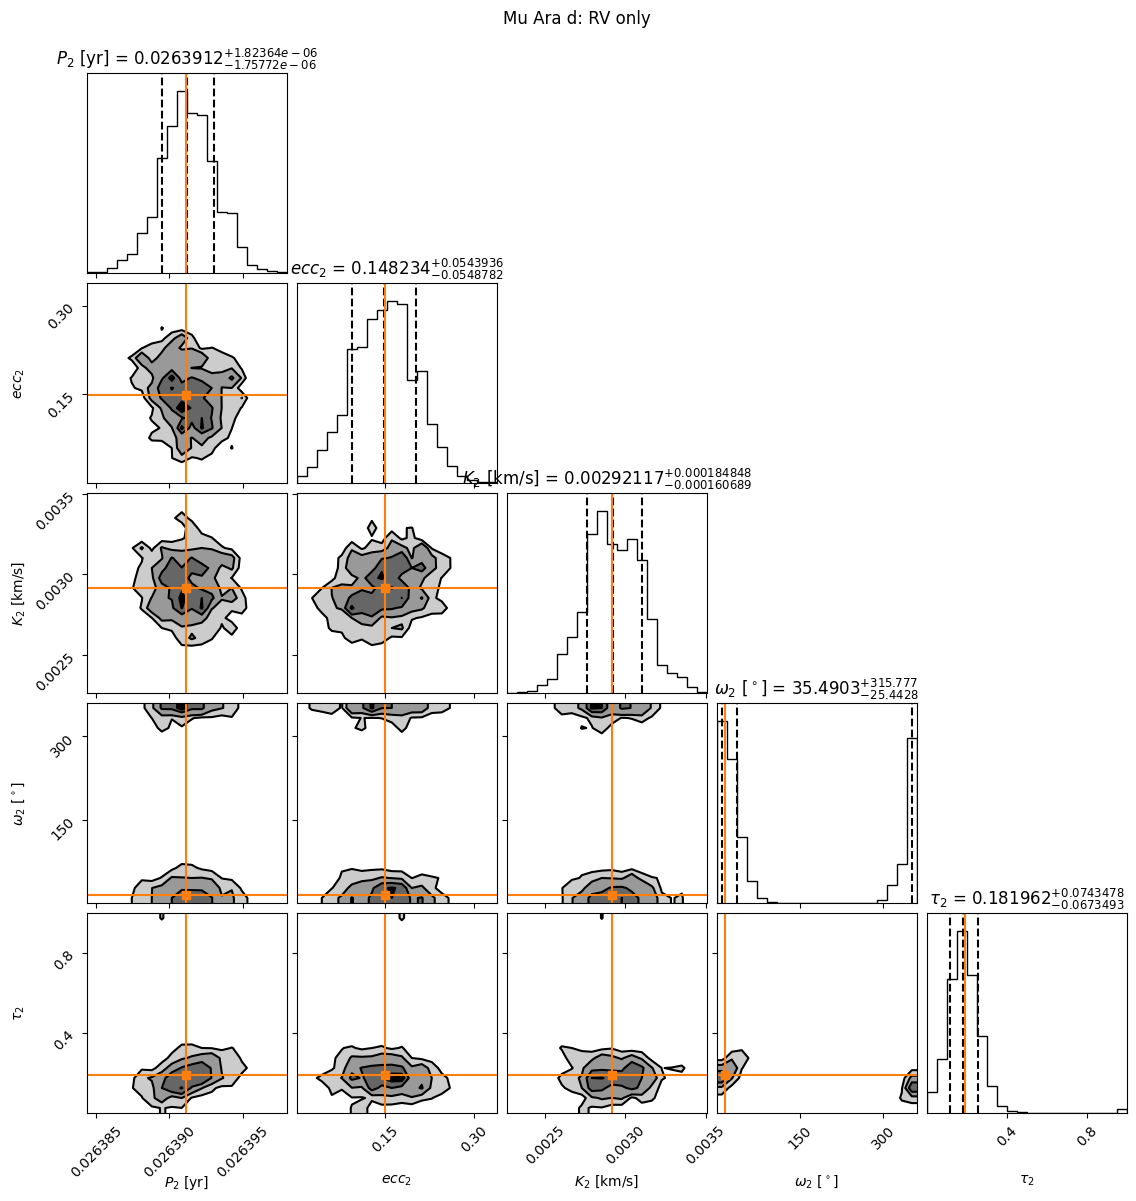

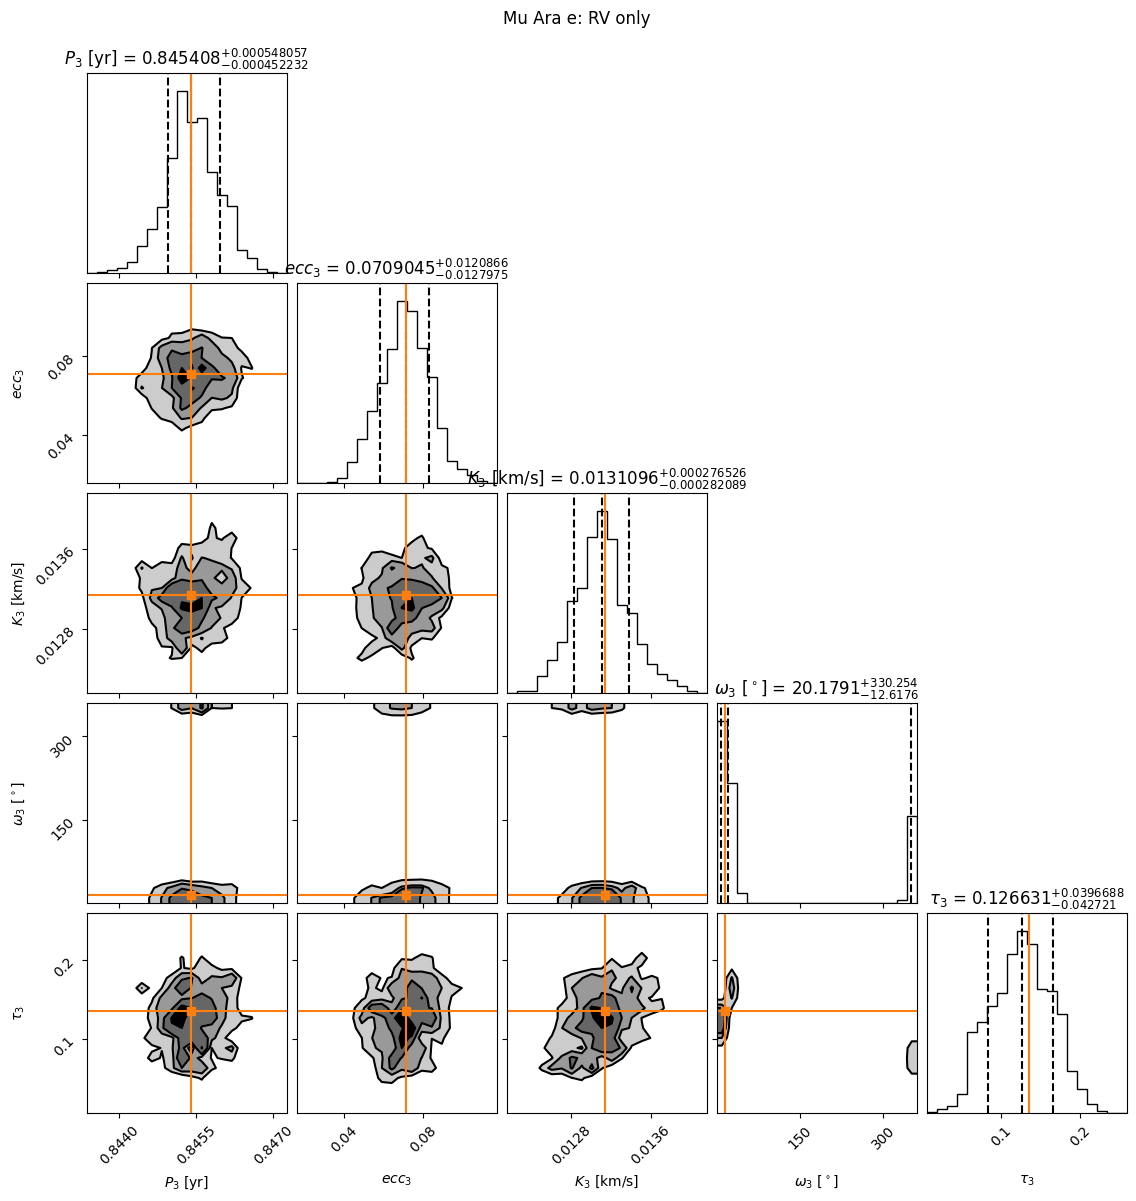

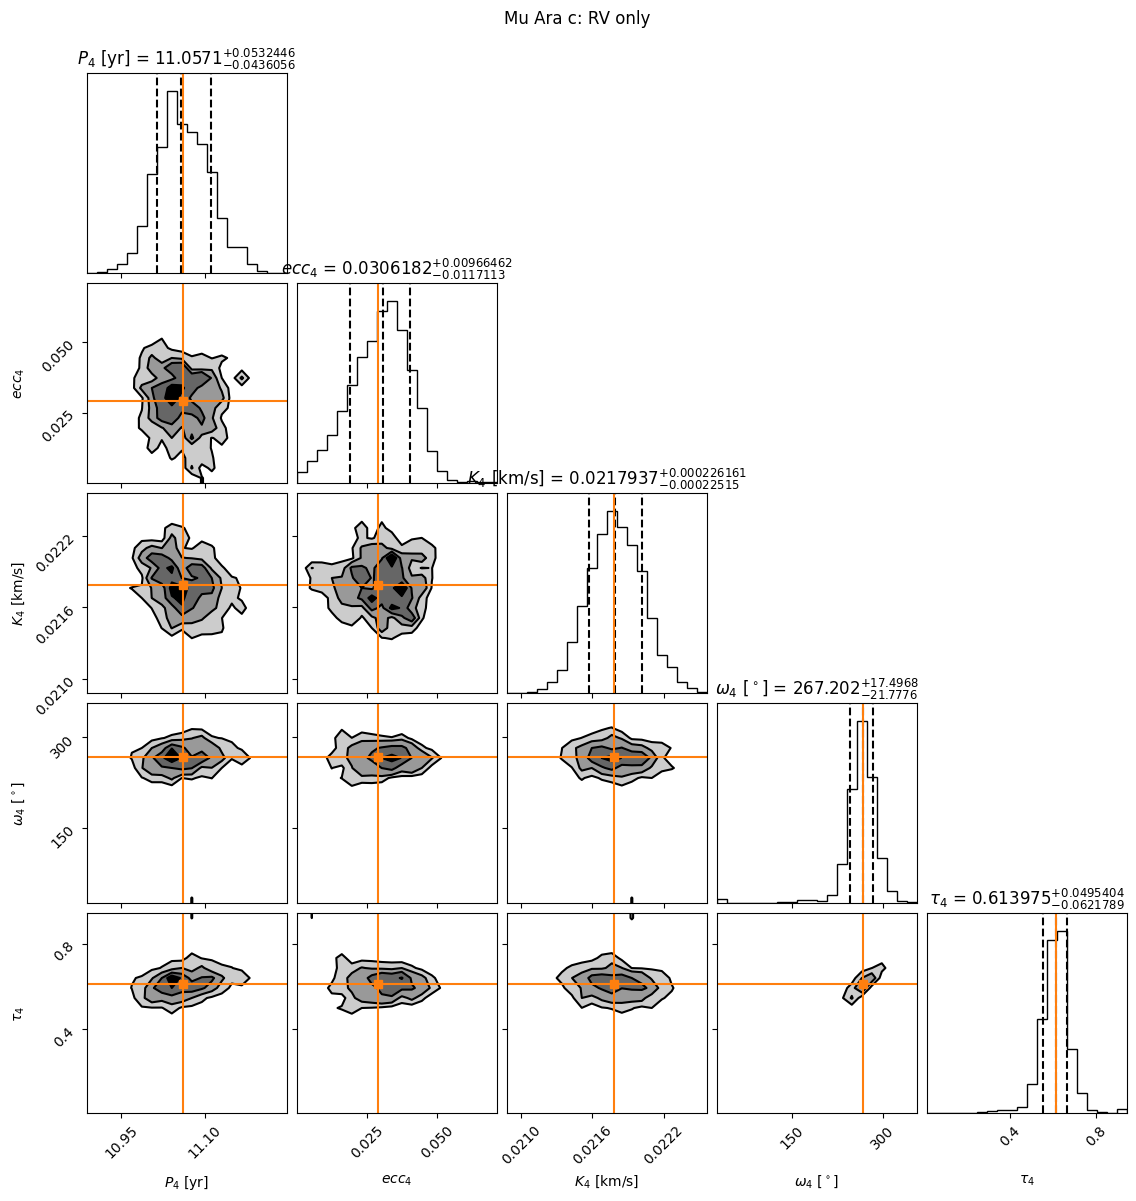

In [6]:
# P [yr], e, K [km/s], companion omega [deg], tau.
# Angle/phase medians account for wrapping.
roman_medians = {
    1: [644.774929/365.25, 0.063219, 0.0354966, 196.5007, 0.925242],
    2: [9.639351/365.25,   0.148987, 0.0029156, 15.3009,  0.190784],
    3: [308.780523/365.25, 0.071187, 0.0131380, 15.0391,  0.134891],
    4: [4039.743321/365.25, 0.029013, 0.0217862, 267.1495, 0.611904],
}

assert m.system.tau_ref_epoch == 58849

with plt.style.context("default"):
    for body, letter in enumerate(("b", "d", "e", "c"), start=1):
        fig = plot.plot_corner(
            m.results,
            param_list=[f"{p}{body}" for p in ("per", "ecc", "K", "aop", "tau")],
            plot_priors=False,
            downsample=min(20_000, len(m.results.post)),
            truths=roman_medians[body],
            truth_color="tab:orange",
            quantiles=[0.16, 0.5, 0.84],
            show_titles=True, title_fmt=".6g",
            plot_datapoints=False, fill_contours=True,
            max_n_ticks=3,
        )
        fig.suptitle(f"Mu Ara {letter}: RV only", y=1.02)
        plt.show()

## 6. Simulate Gaia DR4 astrometry

We start with the highest likelihood draw from the RV-only fit and
give all four planets the same injected inclination ($60^\circ$) and
longitude of the ascending node ($120^\circ$). We then recompute the
planet masses and semimajor axes at that orientation.

The simulator uses the Gaia Observation Forecast Tool (GOST) transit
times and scan angles in `mu_ara_gost_raw.csv`. It projects the star’s
combined orbital reflex motion, proper motion, and parallax onto each
scan direction and adds Gaussian noise based on the star’s Gaia
magnitude ($G = 4.94$). This produces 74 mock transits with a reported
along scan uncertainty of about 0.125 mas per transit.

The injected orbit gives us a known reference for evaluating the joint fit.

In [7]:
rv_system = m.system
rv_idx = rv_system.param_idx
bodies = range(1, rv_system.num_secondary_bodies + 1)

# Take the highest likelihood RV draw and inject a common orientation.
truth_fit = m.results.post[np.nanargmax(m.results.lnlike)].copy()
inc, lan = np.deg2rad([60.0, 120.0])

for body in bodies:
    truth_fit[rv_idx[f"inc{body}"]] = inc
    truth_fit[rv_idx[f"pan{body}"]] = lan

# Convert to the simulator's basis using the injected inclinations.
standard = rv_system.basis.to_standard_basis(truth_fit.copy())
standard_idx = rv_system.basis.standard_basis_idx
names = ["plx", "m0"] + [
    f"{name}{body}"
    for body in bodies
    for name in ("sma", "ecc", "inc", "aop", "pan", "tau", "m")
]
truth_params = {name: float(standard[standard_idx[name]]) for name in names}
truth_params.update(alpha0=0.0, delta0=0.0, pm_ra=-15.034, pm_dec=-190.901)

DR4_REF_EPOCH_MJD = dr4_sim.DR4_REF_EPOCH_MJD
gost_file = Path(DATADIR) / "mu_ara_gost_raw.csv"

dr4_mock = dr4_sim.simulate_dr4(
    gost_file, truth_params,
    g_mag=4.942752,
    seed=160691,
    tau_ref_epoch=rv_system.tau_ref_epoch,
)

print(f"Simulated transits: {len(dr4_mock)}")
print(f"AL uncertainty: {dr4_mock['centroid_pos_error_al'][0]:.3f} mas")
dr4_mock[:5]

Simulated transits: 74
AL uncertainty: 0.125 mas


source_id,transit_id,obs_time_tcb,parallax_factor_al,parallax_factor_ac,scan_pos_angle,field_of_view,centroid_pos_al,centroid_pos_error_al,ra_offset_al,quant_al,sigma_al
,,d,,,rad,,mas,mas,,,
int64,int64,float64,float64,float64,float64,str4,float64,float64,float64,float64,float64
0,0,56906.20171300182,0.6883966469460991,0.7211775240623786,-0.8500294932226227,FoVP,366.9312205544343,0.12475569793288001,366.9312205544343,366.9312205544343,0.12475569793288001
0,1,56906.27571403794,0.6876111169772068,0.7222132518740163,-0.8481287836239148,FoVF,367.7153678371053,0.12475569793288001,367.7153678371053,367.7153678371053,0.12475569793288001
0,2,56941.33107358031,0.6417226053931399,0.7151074927032902,-0.5251610623943874,FoVP,469.97479195549914,0.12475569793288001,469.97479195549914,469.97479195549914,0.12475569793288001
0,3,56941.40507466439,0.6429943283663155,0.7134780208706066,-0.5265984857610458,FoVF,469.69145834712185,0.12475569793288001,469.69145834712185,469.69145834712185,0.12475569793288001
0,4,57082.476959182415,-0.6592544434281691,0.7025423356548718,-2.500750022441162,FoVF,-420.5780256223671,0.12475569793288001,-420.5780256223671,-420.5780256223671,0.12475569793288001


## 7. Set up the joint RV and Gaia fit

We retain the original RV data and priors and add a likelihood for the
mock Gaia along scan measurements. We fit an additional Gaia jitter term
with a uniform prior from 0 to 5 mas. The likelihood adds this term in
quadrature to each transit’s reported uncertainty.

We initialize each walker with one draw from the RV-only posterior for
the shared parameters.



In [9]:

rv_sys = m.system
rv_post = np.asarray(m.results.post)

dr4 = gaia.DR4LogProb(
    0, dr4_mock, ref_epoch_mjd=DR4_REF_EPOCH_MJD,
    jitter_prior=priors.UniformPrior(0.0, 5.0),  # mas
)
joint_system = system.System(
    rv_sys.num_secondary_bodies, rv_sys.data_table.copy(),
    rv_sys.stellar_or_system_mass, rv_sys.plx,
    mass_err=rv_sys.mass_err, plx_err=rv_sys.plx_err,
    fit_secondary_mass=True, fitting_basis=rv_sys.fitting_basis,
    tau_ref_epoch=rv_sys.tau_ref_epoch,
    restrict_angle_ranges=rv_sys.restrict_angle_ranges, gaia=dr4,
)

# Keep the original RV priors.
jidx = joint_system.param_idx
for name, col in rv_sys.param_idx.items():
    joint_system.sys_priors[jidx[name]] = deepcopy(rv_sys.sys_priors[col])

joint_mcmc = sampler.MCMC(
    joint_system, num_temps=m.num_temps, num_walkers=128,
    num_threads=m.num_threads,
)
sidx = joint_mcmc.sampled_param_idx
pos = joint_mcmc.curr_pos.reshape(-1, joint_mcmc.num_params).copy()

# Copy one correlated RV draw per walker, leaving inclination, node and jitter broad.
shared = [
    name for name in sidx
    if name in rv_sys.param_idx and not name.startswith(("inc", "pan"))
]
rows = np.random.default_rng(160692).integers(len(rv_post), size=len(pos))
pos[:, [sidx[n] for n in shared]] = rv_post[rows][:, [rv_sys.param_idx[n] for n in shared]]

# Solve for position and proper motion at each starting orbit.
full = joint_mcmc._fill_in_fixed_params(pos)
ra, dec, _, _ = joint_system.compute_all_orbits(
    full.T, epochs=dr4.epochs_mjd, params_basis="fitting",
)
s, c = dr4.sin_scan, dr4.cos_scan
orbit_al = ra[:, 0, :] * s[:, None] + dec[:, 0, :] * c[:, None]
linear_cols = [sidx[n] for n in ("alpha0", "delta0", "pm_ra", "pm_dec")]

gaia_times = Time(dr4.epochs_mjd, format="mjd", scale=dr4.time_scale)
gaia_ref_year = Time(dr4.ref_epoch_mjd, format="mjd", scale=dr4.time_scale).jyear

for i, p in enumerate(full):
    target = dr4.centroid_pos_al - orbit_al[:, i] - p[jidx["plx"]] * dr4.parallax_factor_al
    sigma = np.hypot(dr4.centroid_pos_error_al, p[jidx["dr4_jitter"]])
    pos[i, linear_cols] = gaia.HGCALogProb._linear_pm_fit(
        gaia_times, target * s, target * c,
        gaia_ref_year, gaia_ref_year, c, s, sigma,
    )

joint_mcmc.curr_pos = pos.reshape(joint_mcmc.curr_pos.shape)
joint_mcmc.check_prior_support()
print(f"Ready: {len(rv_sys.data_table)} RVs + {dr4.n_obs} Gaia transits")

Ready: 487 RVs + 74 Gaia transits


In [10]:
joint_run = joint_mcmc.run_sampler(
    joint_mcmc.num_walkers * 1_000,
    burn_steps=500,
    thin=1,
)
joint_post = joint_mcmc.results.post

print(f"Joint posterior samples: {len(joint_post):,}")
print(f"Cold-chain acceptance: {joint_run.acceptance_fraction[0].mean():.3f}")
print(f"Best joint logL: {np.nanmax(joint_mcmc.results.lnlike):.2f}")

Starting Burn in


/Users/clary/Projects/orbitize-mu-ara/orbitize/priors.py:566: RuntimeWarning: invalid value encountered in log
  lnprob = np.log(np.sin(element_array) / normalization)
/Users/clary/Projects/orbitize-mu-ara/orbitize/priors.py:566: RuntimeWarning: invalid value encountered in log
  lnprob = np.log(np.sin(element_array) / normalization)
/Users/clary/Projects/orbitize-mu-ara/orbitize/priors.py:566: RuntimeWarning: invalid value encountered in log
  lnprob = np.log(np.sin(element_array) / normalization)
/Users/clary/Projects/orbitize-mu-ara/orbitize/priors.py:566: RuntimeWarning: invalid value encountered in log
  lnprob = np.log(np.sin(element_array) / normalization)
/Users/clary/Projects/orbitize-mu-ara/orbitize/priors.py:566: RuntimeWarning: invalid value encountered in log
  lnprob = np.log(np.sin(element_array) / normalization)
/Users/clary/Projects/orbitize-mu-ara/orbitize/priors.py:566: RuntimeWarning: invalid value encountered in log
  lnprob = np.log(np.sin(element_array) / normali

500/500 steps of burn-in complete
Burn in complete. Sampling posterior now.


/Users/clary/Projects/orbitize-mu-ara/orbitize/priors.py:417: RuntimeWarning: invalid value encountered in log
  lnprob = -np.log((element_array * normalizer))


1000/1000 steps completed
Run complete
Joint posterior samples: 128,000
Cold-chain acceptance: 0.063
Best joint logL: 2214.62


## 8. Compare the joint posteriors with the injected orbit

We make one corner plot per planet in the fit order (b, d, e, c).
Each plot shows the joint posterior for period, eccentricity,
inclination, longitude of the ascending node (LAN), and RV
semi-amplitude. The same Gaia jitter parameter appears in all
four plots because it is shared across the system.

Orange lines mark the values used to generate the mock Gaia data.
All four planets were injected at an inclination of $60^\circ$ and
a LAN of $120^\circ$.

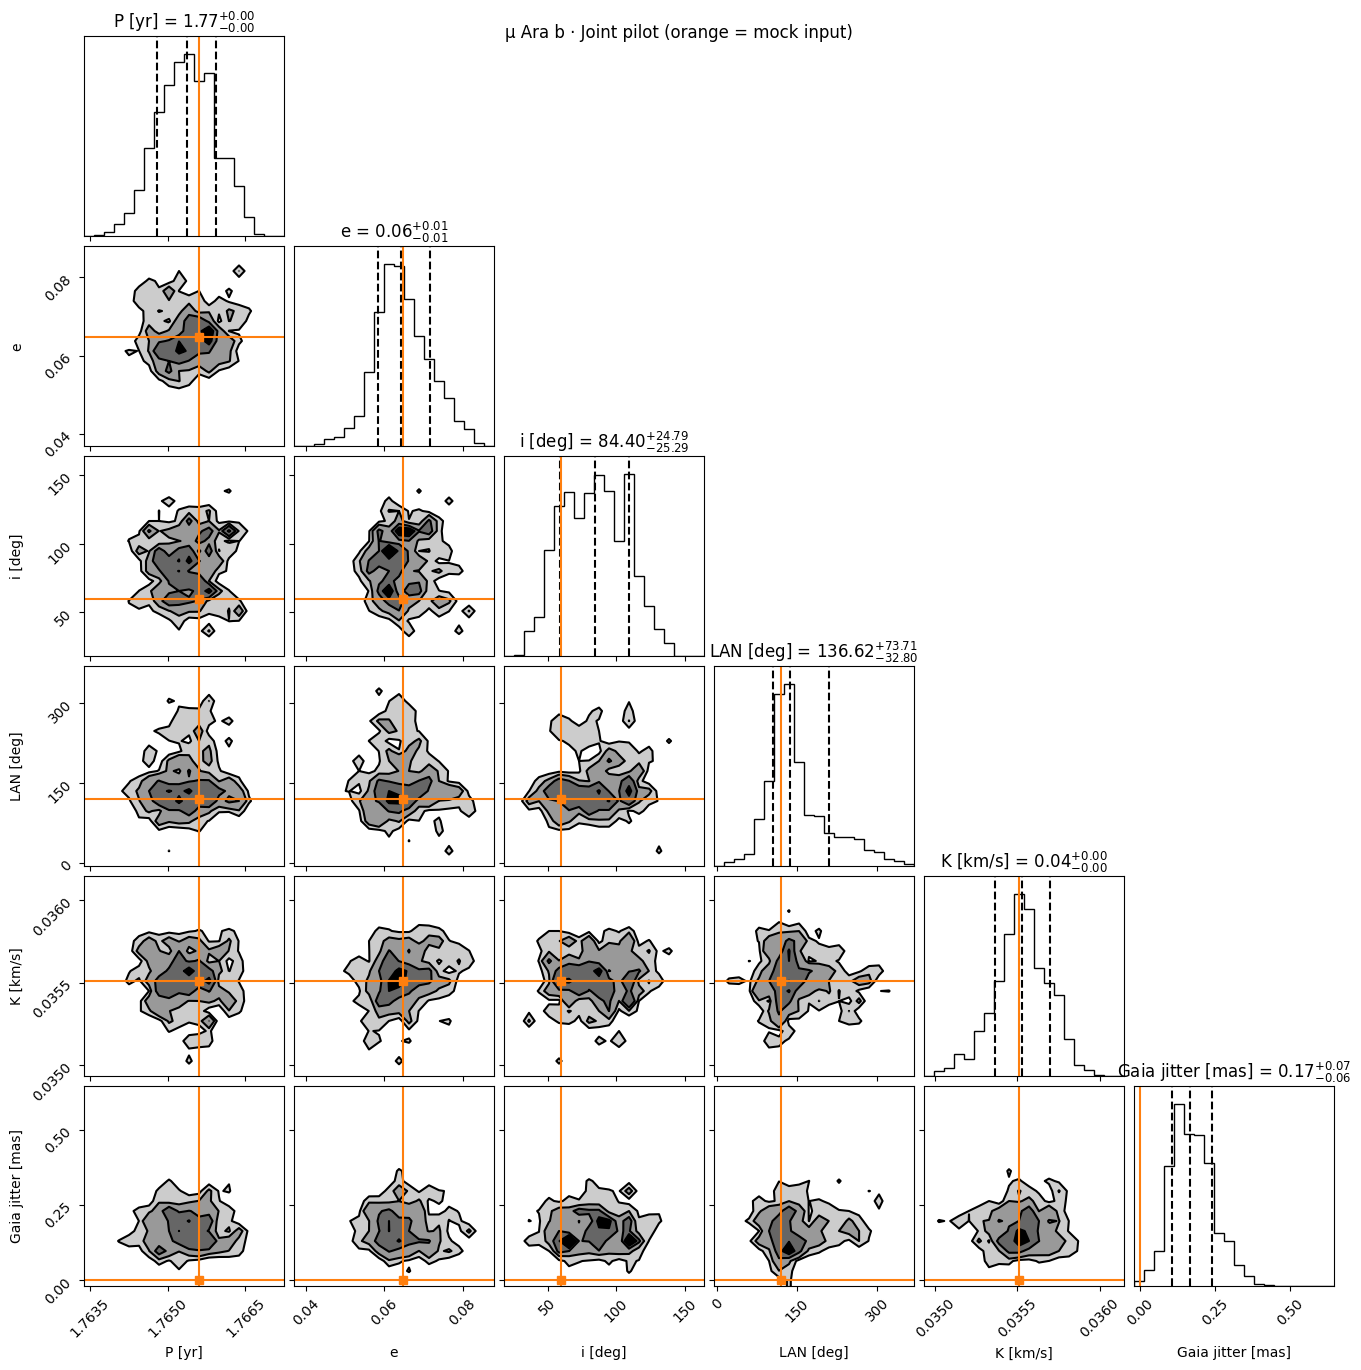

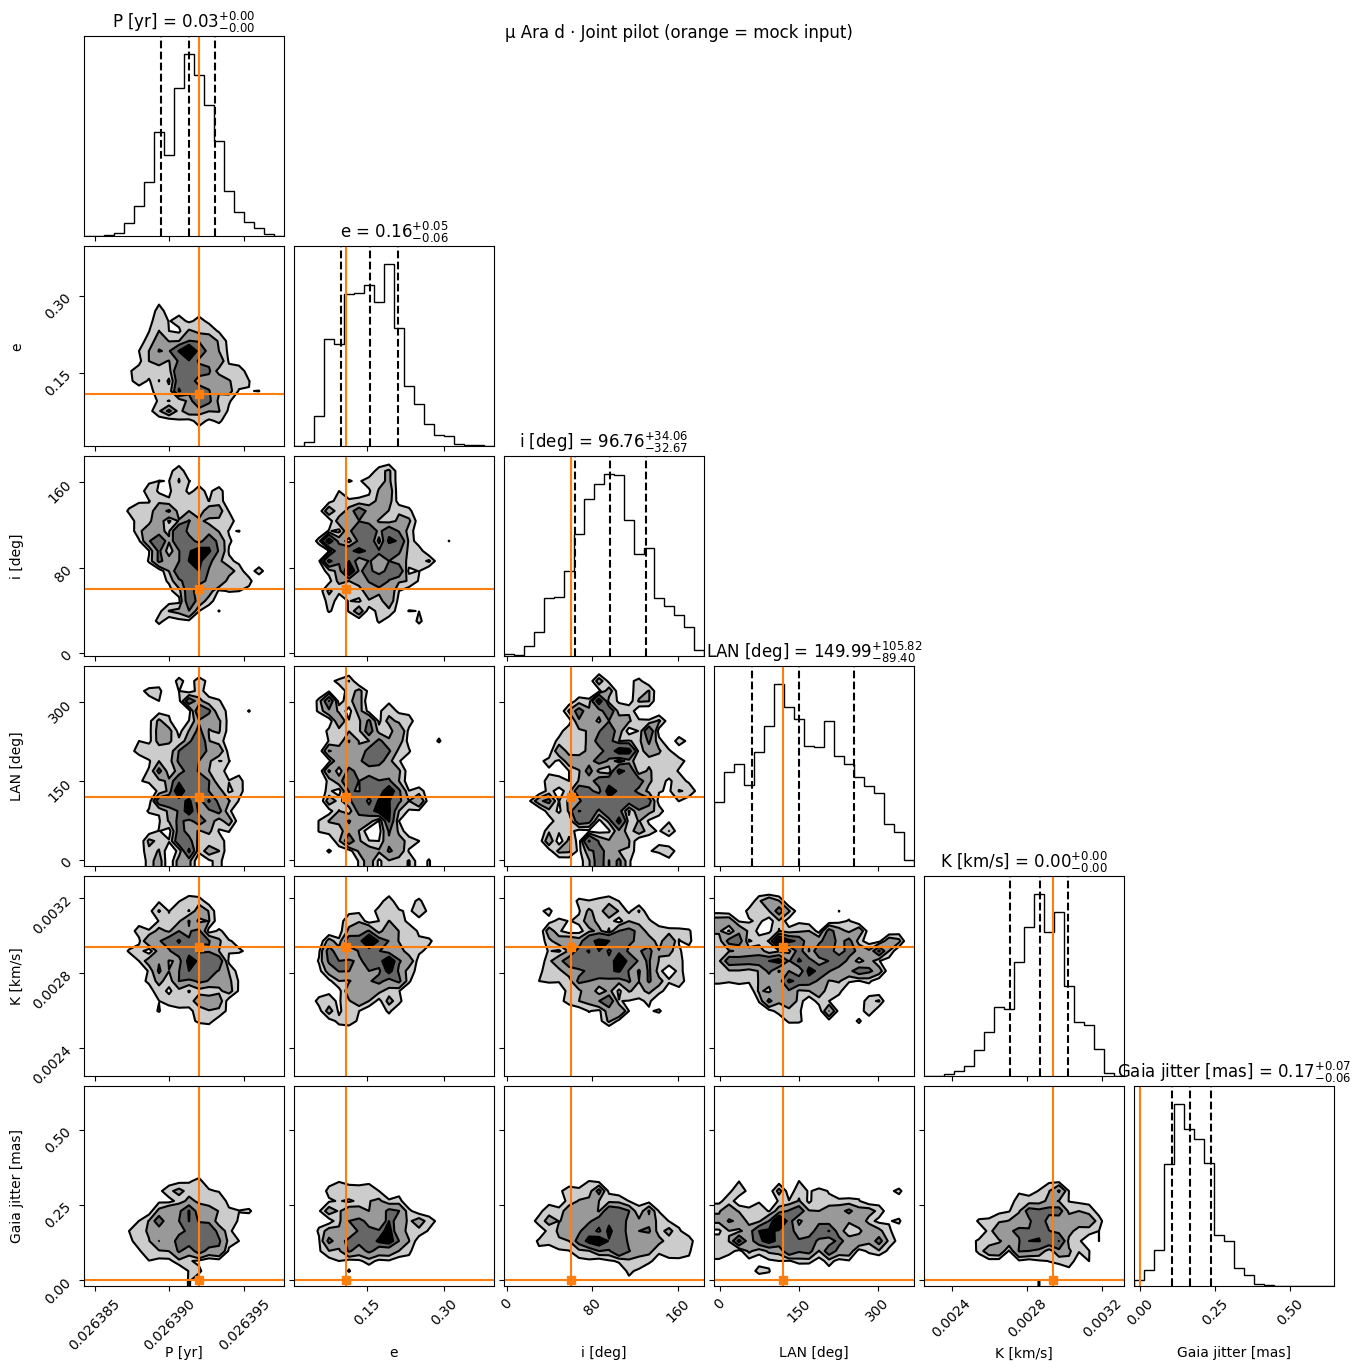

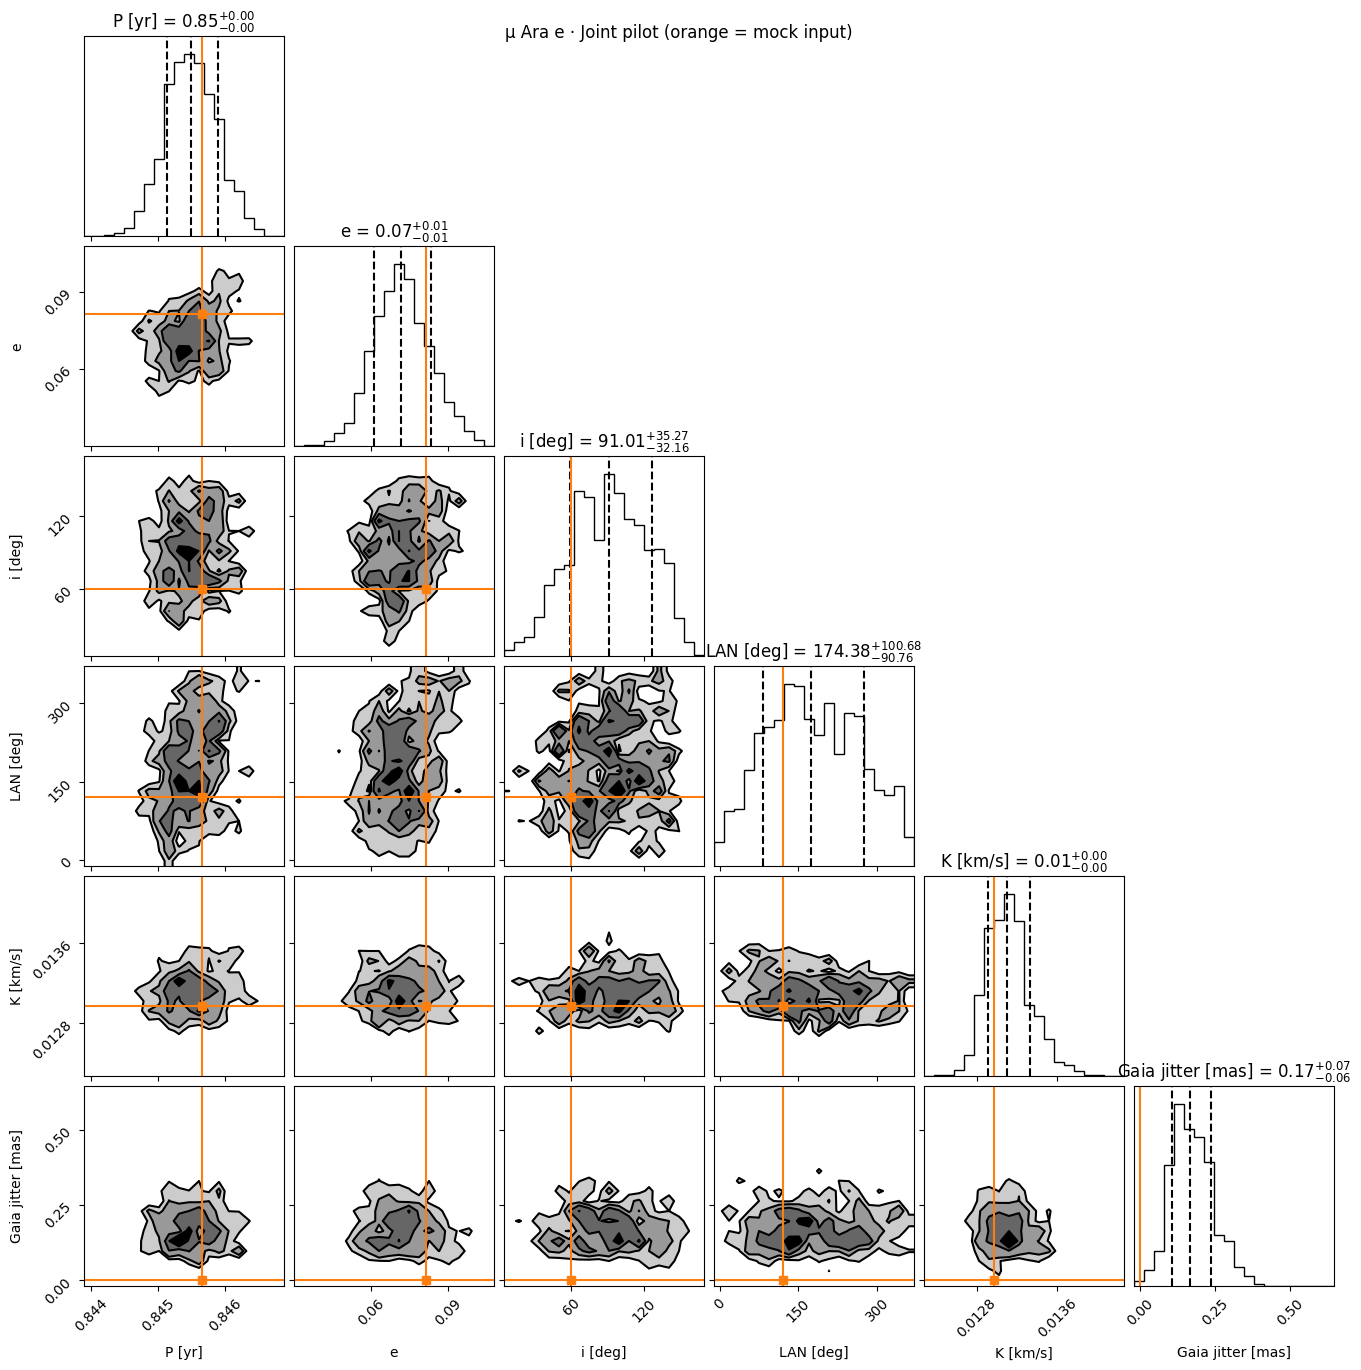

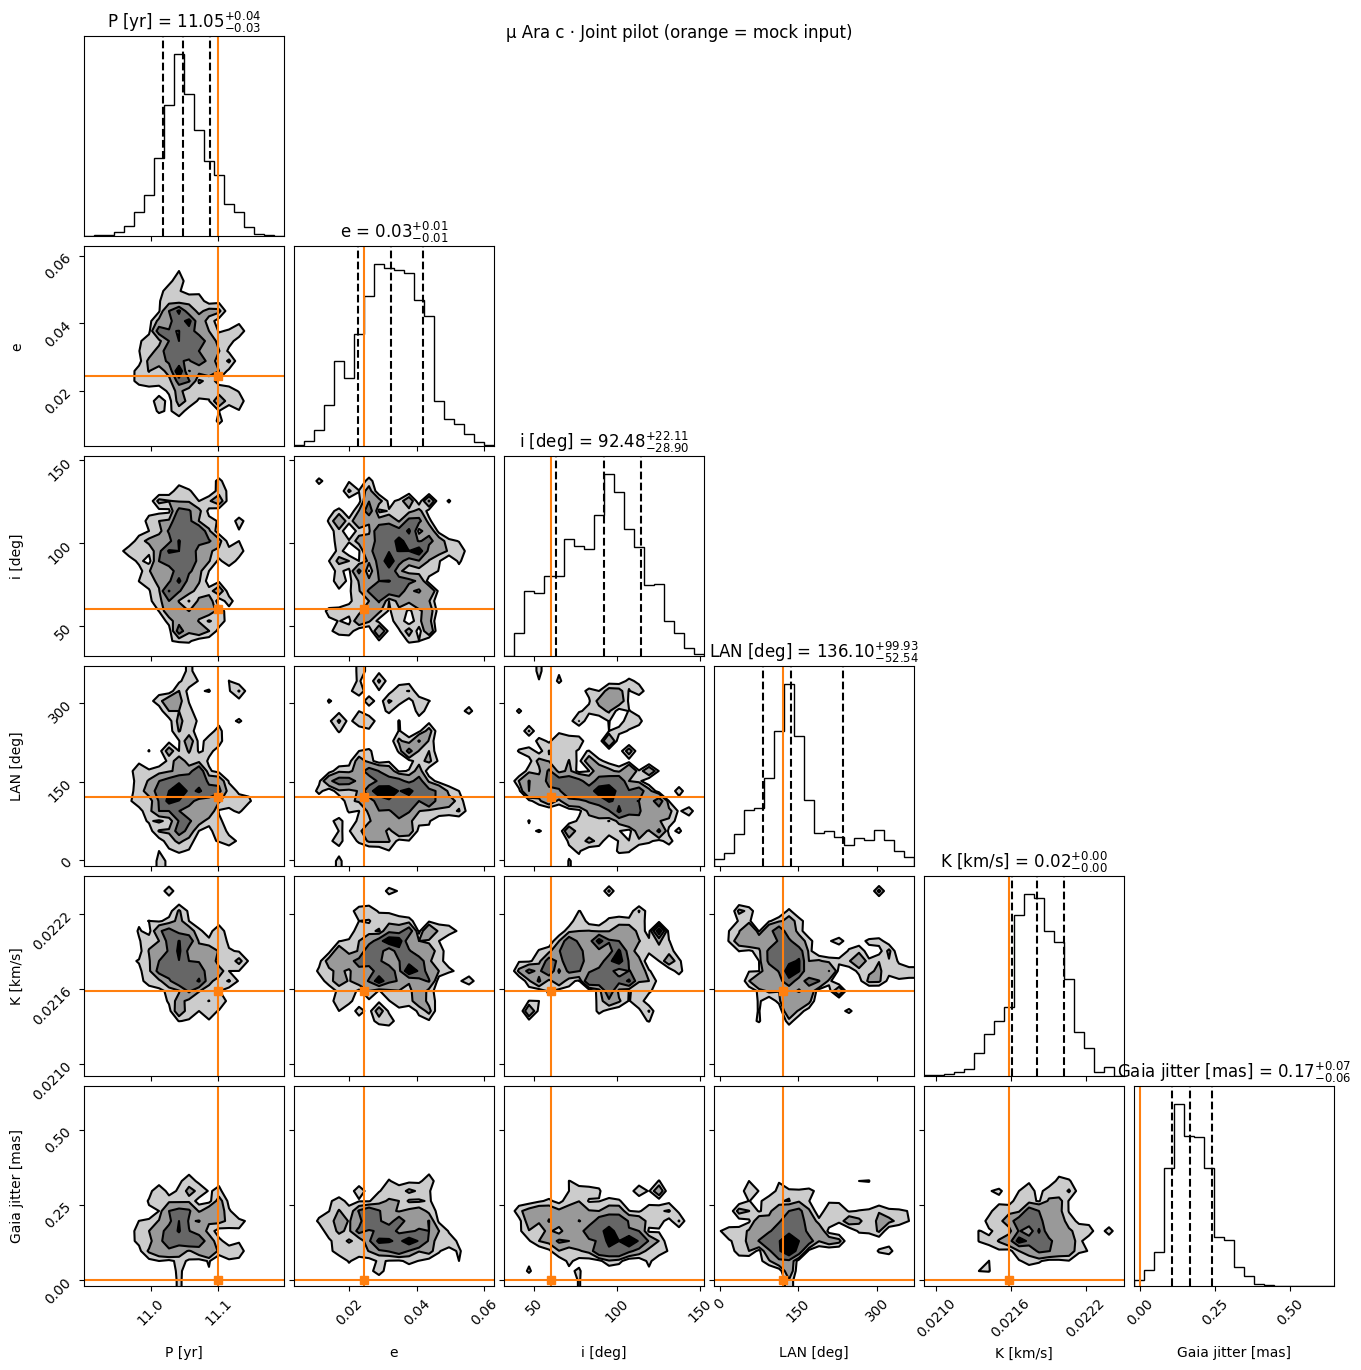

In [11]:

joint_results = joint_mcmc.results
rv_idx = m.system.param_idx
planets = ("b", "d", "e", "c")  # order in the fit

with plt.style.context("default"):
    for body, planet in enumerate(planets, start=1):
        orbital_names = [
            f"{name}{body}" for name in ("per", "ecc", "inc", "pan", "K")
        ]
        names = orbital_names + ["dr4_jitter"]
        truths = [float(truth_fit[rv_idx[name]]) for name in orbital_names]
        truths[2:4] = np.rad2deg(truths[2:4]).tolist()
        truths.append(0.0)

        # Keep the orange lines visible even outside the sampled range.
        samples = joint_results.post[
            :, [joint_results.param_idx[name] for name in names]
        ].copy()
        samples[:, 2:4] = np.rad2deg(samples[:, 2:4])
        lo = np.minimum(samples.min(axis=0), truths)
        hi = np.maximum(samples.max(axis=0), truths)
        pad = 0.03 * (hi - lo)

        fig = plot.plot_corner(
            joint_results,
            param_list=names,
            labels=["P [yr]", "e", "i [deg]", "LAN [deg]", "K [km/s]", "Gaia jitter [mas]"],
            truths=truths,
            truth_color="tab:orange",
            range=list(zip(lo - pad, hi + pad)),
            plot_priors=False,
            downsample=min(20_000, len(joint_results.post)),
            quantiles=[0.16, 0.50, 0.84],
            show_titles=True,
            plot_datapoints=False,
            fill_contours=True,
            max_n_ticks=3,
        )
        fig.suptitle(f"μ Ara {planet} · Joint pilot (orange = mock input)")
        plt.show()

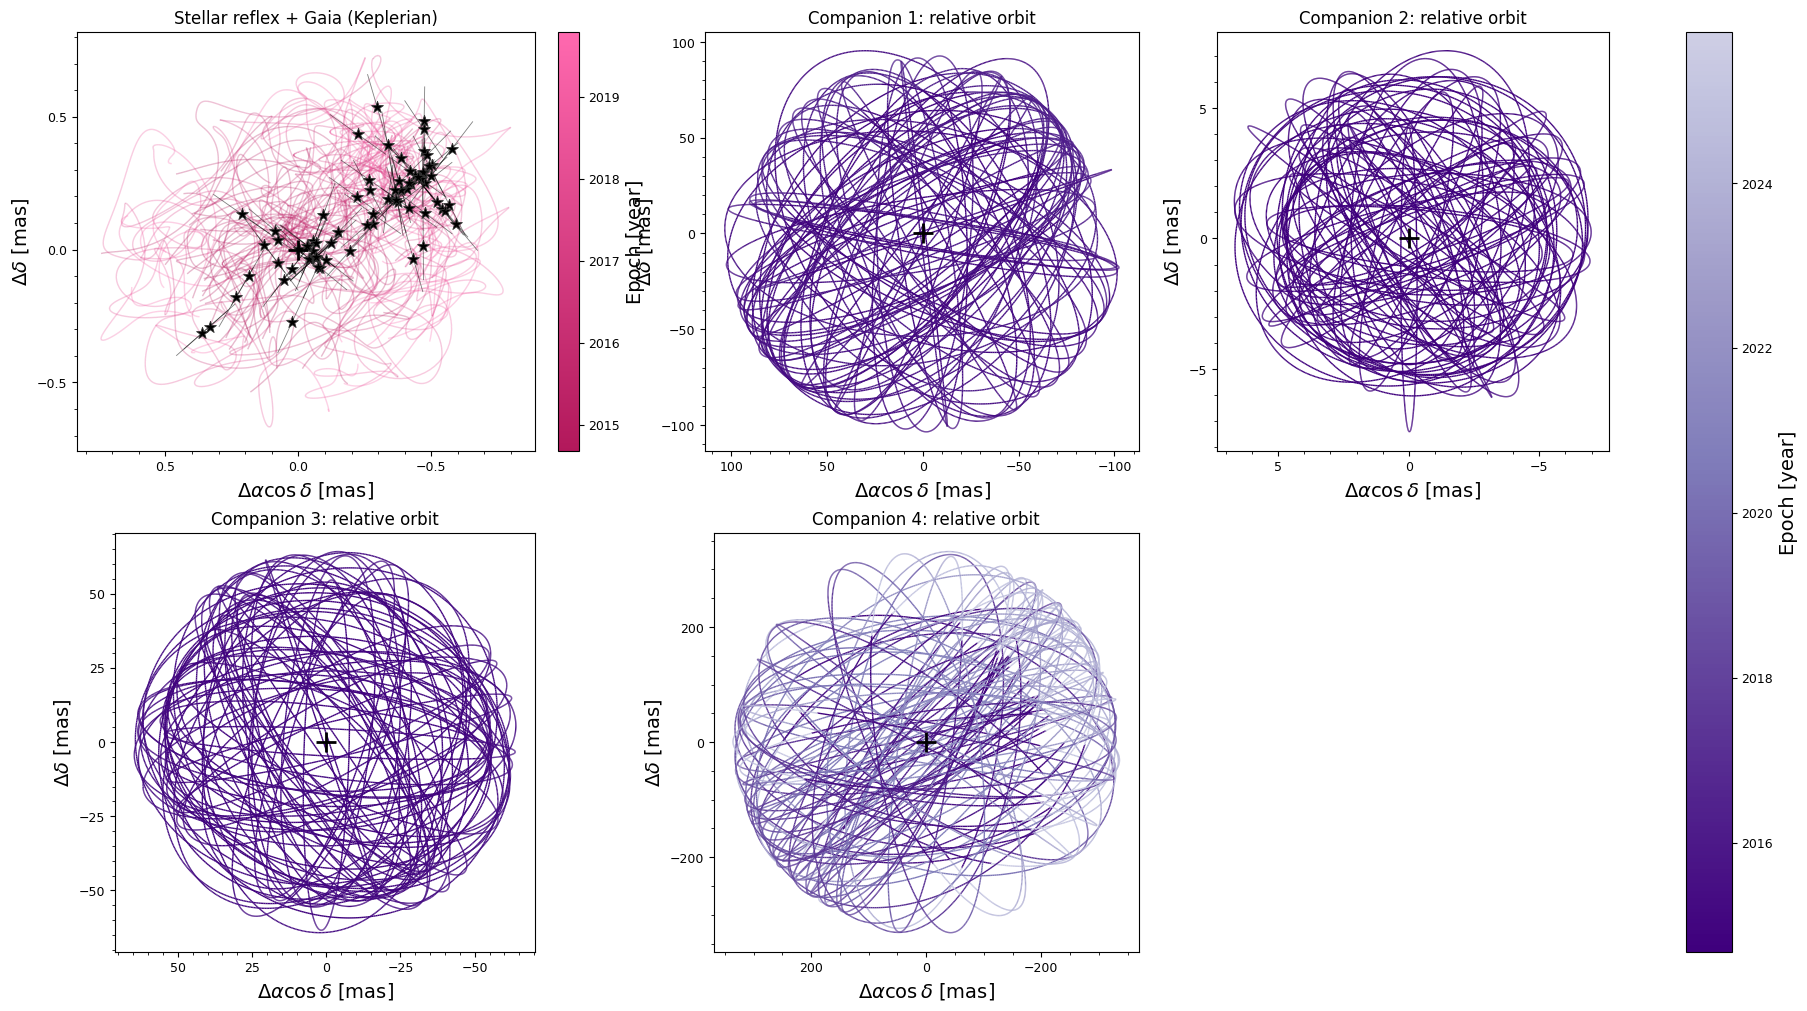

In [13]:

fig = plot.Plotter.plot_dr4_orbit(
    joint_mcmc.results,
    joint_mcmc.system,
    include_planet=True,
    planet_to_plot=[1, 2, 3, 4],  # b, d, e, c
    num_orbits_to_plot=60,
    include_jitter=True,
    fontsize=14,
)